# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170101         # <-- your full roll number
NAME = "HarsimratSingh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170101   Name: HarsimratSingh   Fingerprint: 81B07B19   Tickets: 13

Ticket_ID                                                                                       Ticket_Text
      T01                                                                     Why isn't the portal opening?
      T02                                                                   Is it fixed?? Pls reply ASAP :(
      T03                                                              Python 3.12 was installed yesterday.
      T04                                  The e-mail keeps asking for login. It works on another computer.
      T05                         Projector crashes while opening after restarting the system. Please help.
      T06              Laptop stopped responding after resetting my password. It works on another computer.
      T07                       VPN has stopped syncing after the latest update. Is there another solution?
      T08                       I was locked out o

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code
import pandas as pd

rows = []
for idx, row in df.iterrows():
    stats = process_ticket(row['Ticket_Text'])
    rows.append({
        'sentences': len(stats['sentences']),
        'tokens': len(stats['tokens']),
        'punctuation tokens': len(stats['punct']),
        'stopwords': len(stats['stops']),
        'unique tokens': len(set(stats['tokens'])),
        'final tokens': len(stats['final'])
    })

df_q1 = pd.DataFrame(rows, index=df['Ticket_ID'])
df_q1.loc['TOTAL'] = df_q1.sum()
print(df_q1.to_string())

focus_id = FOCUS[0] if FOCUS else 'T01'
focus_row = df[df['Ticket_ID'] == focus_id].iloc[0]
focus_stats = process_ticket(focus_row['Ticket_Text'])
print(f"\nSelected Ticket ({focus_id}) Breakdown")
print("Text:", focus_row['Ticket_Text'])
print("Sentences:", focus_stats['sentences'])
print("Tokens:", focus_stats['tokens'])
print("Punctuation Tokens:", focus_stats['punct'])
print("Stopwords:", focus_stats['stops'])
print("Final Tokens:", focus_stats['final'])

           sentences  tokens  punctuation tokens  stopwords  unique tokens  final tokens
Ticket_ID                                                                               
T01                1       7                   1          3              7             3
T02                2      10                   4          2              9             4
T03                1       6                   1          1              6             4
T04                2      13                   2          4             12             7
T05                2      12                   2          3             11             7
T06                2      14                   2          4             13             8
T07                2      14                   2          5             14             7
T08                2      16                   2          8             14             6
T09                2      13                   2          5             12             6
T10                2 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

Tokens such as n't,'s,ca were created during tokenization from word like couldn't,don't etc. This happens beecause when stopwords like could and do are filtered out remaining part of the word remains and is considered as a seperate token by the program.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re
all_text = " ".join(df['Ticket_Text'])

words_gt_5 = re.findall(r'\b[A-Za-z]{6,}\b', all_text)

numbers = re.findall(r'\b\d+(?:\.\d+)*%?\b', all_text)

# 3. Capitalized words
cap_words = re.findall(r'\b[A-Z][a-z]+\b', all_text)

# 4. Words beginning with a vowel
vowel_words = re.findall(r'\b[AEIOUaeiou][A-Za-z]+\b', all_text)

# 5. re.sub replacements for emails, URLs, and phone numbers
def clean_text(text):
    text = re.sub(r'[\w\.-]+@[\w\.-]+\.\w+', '<EMAIL>', text)
    text = re.sub(r'https?://[^\s]+|www\.[^\s]+', '<URL>', text)
    text = re.sub(r'(?:\+?\d{1,3}[-.\s]?)?(?:\d{5}[-.\s]?\d{5}|\d{3}[-.\s]?\d{3}[-.\s]?\d{4}|\d{4}[-.\s]?\d{3}[-.\s]?\d{4})', '<PHONE>', text)
    return text

print("Regex Replacement")
for line in TEST_LINES:
    print(clean_text(line))

Regex Replacement
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
# Your code
import pandas as pd
from nltk.tokenize import RegexpTokenizer, word_tokenize


pattern = r"""(?x)                  # set flag to allow verbose regexps
    https?://\S+|www\.\S+          # URLs
  | [\w\.-]+@[\w\.-]+\.\w+         # Emails
  | (?:\+\d{1,3}[-.\s]?)?\(?\d{3,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{4} # Phone numbers
  | \d+(?:\.\d+)+%?                # Versions / Decimals (e.g. 2.0.1, 95.5%)
  | \b\w+(?:-\w+)+\b               # Hyphenated words (e.g. Wi-Fi, state-of-the-art)
  | \b\w+(?:'\w+)?\b               # Words with contractions (e.g. isn't, can't)
  | [^\s\w]                        # Any other single non-whitespace punctuation
"""

custom_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)


print("=== Custom Tokenizer Output on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {i}: {line}")
    print("Tokens:", my_tokenize(line))

diff_count = 0
print("\n=== Tokenizer Comparison on Tickets ===")

for idx, row in df.iterrows():
    text = row['Ticket_Text']
    t_id = row['Ticket_ID']
    my_toks = my_tokenize(text)
    nltk_toks = word_tokenize(text)

    if my_toks != nltk_toks:
        diff_count += 1
        print(f"\n[{t_id}] Raw Text: {text}")
        print(f"  my_tokenize   : {my_toks}")
        print(f"  word_tokenize : {nltk_toks}")



=== Custom Tokenizer Output on TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Tokens: ['Call', '+', '91', '98765', '43210', ',', '+', '91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Tokens: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

=== Tokenizer Comparison on Tickets ===

[T01] Raw Text: Why isn't the portal opening?
  my_tokenize   : ['Why', "isn't", 'the', 'portal', 'opening', '?']
  word_tokenize : ['Why', 'i

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 10 out of 13 tickets were tokenized differently

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
# Your code
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

all_final_tokens = []
for idx, row in df.iterrows():
    stats = process_ticket(row['Ticket_Text'])
    all_final_tokens.extend(stats['final'])

unique_final_tokens = sorted(list(set(all_final_tokens)))

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer('ing$', min=4)

lemmatizer = WordNetLemmatizer()
pos_tags = nltk.pos_tag(unique_final_tokens)

differing_rows = []

for (token, tag) in pos_tags:
    p_stem = porter.stem(token)
    l_stem = lancaster.stem(token)
    r_stem = regexp_stemmer.stem(token)

    wn_pos = get_wordnet_pos(tag)
    wn_lemma = lemmatizer.lemmatize(token, pos=wn_pos)

    if not (p_stem == l_stem == r_stem == wn_lemma):
        differing_rows.append({
            'Original Token': token,
            'POS Tag': tag,
            'Porter': p_stem,
            'Lancaster': l_stem,
            'RegexpStemmer': r_stem,
            'WordNet Lemmatizer': wn_lemma
        })
df_q4 = pd.DataFrame(differing_rows)

print("Stemming vs. Lemmatization Comparison Table")
print(df_q4.to_string(index=False))

=== Q4: Stemming vs. Lemmatization Comparison Table ===
Original Token POS Tag    Porter Lancaster RegexpStemmer WordNet Lemmatizer
       another      DT     anoth     anoth       another            another
    assignment      NN    assign    assign    assignment         assignment
       changed     VBD     chang     chang       changed             change
      computer      NN    comput    comput      computer           computer
       crashes      VB     crash     crash       crashes              crash
      deadline      JJ   deadlin   deadlin      deadline           deadline
          file      NN      file       fil          file               file
         fixed     VBN       fix       fix         fixed                fix
     installed     VBN    instal    instal     installed             instal
         keeps     NNS      keep      keep         keeps               keep
        latest     JJS    latest    latest        latest               late
           lms      NN        lm

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over stemming: times is reduced to tim in Lancaster
               Understemming: uploading remains uploading in Lemmatizer

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== Corpus Statistics ===
                 Set  Total Tokens  Unique Tokens  TTR (Type-Token Ratio)
     S1 (All Tokens)           158             86                  0.5443
 S2 (No Punctuation)           132             80                  0.6061
   S3 (Final Tokens)            78             58                  0.7436
S4 (S3 after Porter)            78             57                  0.7308

=== Top 10 Words in S1 ===
  .: 18
  the: 14
  i: 5
  is: 4
  ?: 4
  it: 4
  after: 4
  n't: 3
  opening: 3
  another: 3

=== Top 10 Words in S3 ===
  n't: 3
  opening: 3
  another: 3
  restarting: 3
  portal: 2
  keeps: 2
  works: 2
  computer: 2
  projector: 2
  crashes: 2

=== Top 5 Bigrams in S1 ===
  . the: 5
  restarting the: 3
  . i: 3
  . it: 2
  it works: 2

=== Top 5 Bigrams in S3 ===
  works another: 2
  another computer: 2
  crashes opening: 2
  restarting system: 2
  system please: 2


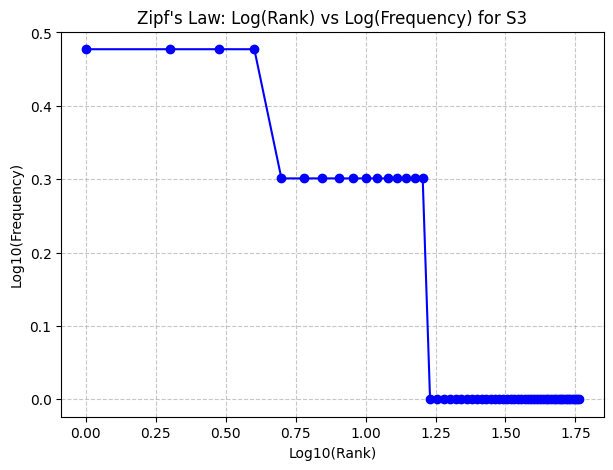

In [11]:
# Your code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import ngrams

# Initialize Porter Stemmer
porter = PorterStemmer()

# 1. Define the 4 Token Sets
s1_tokens = []  # All tokens
s2_tokens = []  # No punctuation tokens
s3_tokens = []  # Final tokens (no punctuation, no stopwords)
s4_tokens = []  # S3 after Porter stemming

for idx, row in df.iterrows():
    stats = process_ticket(row['Ticket_Text'])

    # S1: All tokens (lowercase)
    s1_tokens.extend(stats['tokens'])

    # S2: No punctuation
    s2_tokens.extend([t for t in stats['tokens'] if not is_punct(t)])

    # S3: Final tokens
    s3_tokens.extend(stats['final'])

# S4: S3 after Porter Stemming
s4_tokens = [porter.stem(t) for t in s3_tokens]

# Helper function to compute corpus statistics
def compute_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0.0
    return tot, uniq, ttr

# 2. Build Corpus Statistics Table
sets_data = {
    "S1 (All Tokens)": s1_tokens,
    "S2 (No Punctuation)": s2_tokens,
    "S3 (Final Tokens)": s3_tokens,
    "S4 (S3 after Porter)": s4_tokens
}

stats_rows = []
for set_name, tok_list in sets_data.items():
    tot, uniq, ttr = compute_stats(tok_list)
    stats_rows.append({
        "Set": set_name,
        "Total Tokens": tot,
        "Unique Tokens": uniq,
        "TTR (Type-Token Ratio)": round(ttr, 4)
    })

df_stats = pd.DataFrame(stats_rows)
print("=== Corpus Statistics ===")
print(df_stats.to_string(index=False))

# 3. Top 10 Words for S1 and S3
top10_s1 = Counter(s1_tokens).most_common(10)
top10_s3 = Counter(s3_tokens).most_common(10)

print("\n=== Top 10 Words in S1 ===")
for word, count in top10_s1:
    print(f"  {word}: {count}")

print("\n=== Top 10 Words in S3 ===")
for word, count in top10_s3:
    print(f"  {word}: {count}")

# 4. Top 5 Bigrams for S1 and S3
bigrams_s1 = Counter(list(ngrams(s1_tokens, 2))).most_common(5)
bigrams_s3 = Counter(list(ngrams(s3_tokens, 2))).most_common(5)

print("\n=== Top 5 Bigrams in S1 ===")
for bg, count in bigrams_s1:
    print(f"  {' '.join(bg)}: {count}")

print("\n=== Top 5 Bigrams in S3 ===")
for bg, count in bigrams_s3:
    print(f"  {' '.join(bg)}: {count}")

# 5. Plot log(rank) vs log(frequency) for S3
freqs = [freq for word, freq in Counter(s3_tokens).most_common()]
ranks = np.arange(1, len(freqs) + 1)

log_ranks = np.log10(ranks)
log_freqs = np.log10(freqs)

plt.figure(figsize=(7, 5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-', color='b')
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log10(Rank)")
plt.ylabel("Log10(Frequency)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR increases from S1 to S3 because total number of  words which is a denominator while calculating TTR is getting decreased while in S4 it decreases because number of unique word get reduced so TTR gets lower.